# Задание I. Обусловленность и устойчивость

Используйте написанные функции и тип `float64`. Методы сравнивайте на одинаковых данных.
Ошибки и невязки вычисляйте по исходным матрице и правой части, сохранив их до вызова решателя.
Относительные ошибки решений и невязки считайте в евклидовой норме, обратную погрешность $\text{---}$ в норме $p=1$.

## Обусловленность: направление возмущения

Рассмотрим систему $A_\alpha x=b$ с известным решением $x^*=u$:

$$
A_\alpha=\frac12\begin{bmatrix}1+\alpha & 1-\alpha\\ 1-\alpha & 1+\alpha\end{bmatrix},\qquad
u=\begin{bmatrix}1\\1\end{bmatrix},\qquad
v=\begin{bmatrix}1\\-1\end{bmatrix},\qquad b=u
$$

Возьмите $\alpha=2^{-k}$ при $k=0,10,20,30,40$. Изменим правую часть в двух направлениях:

$$
b_+=b+\theta u,\qquad b_-=b+\theta v,\qquad \theta=2^{-30}
$$

В обоих случаях относительное изменение правой части равно $\theta$.
Все элементы $A_\alpha$, $b$, $b_+$, $b_-$ точно представимы в `float64`.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import NDArray

for _cand in (Path.cwd() / "src", Path.cwd().parent / "src", Path("src")):
    if _cand.is_dir():
        sys.path.insert(0, str(_cand.resolve()))
        break

from decomps.lup import lup_factor
from decomps.qr import qr_factor
from metrics import (
    backward_error_1,
    condition_1_estimate,
    growth_factor,
    relative_error,
)
from solvers.lup_solve import lup_solve
from solvers.qr_solve import qr_solve

DELTA_POWERS = [0, 10, 20, 30, 40]
ETA = 2.0**-30
WILKINSON_SIZES = [8, 16, 32, 48, 64]
METHODS = ("lup", "qr")
RHS_NAMES = ("b", "b+", "b-")
u_round = np.finfo(np.float64).eps / 2

In [2]:
def text_table(headers, rows):
    columns = [[str(h)] + [str(row[j]) for row in rows] for j, h in enumerate(headers)]
    widths = [max(len(cell) for cell in column) for column in columns]

    lines = []
    for i in range(len(rows) + 1):
        values = [
            column[i].ljust(w) if j == 0 else column[i].rjust(w)
            for j, (column, w) in enumerate(zip(columns, widths))
        ]
        lines.append("  ".join(values))
    lines.insert(1, "  ".join("-" * w for w in widths))
    return "\n".join(lines)

In [3]:
u: NDArray = np.array([1.0, 1.0])
v: NDArray = np.array([1.0, -1.0])


def make_A(alpha: float) -> NDArray:
    return 0.5 * np.array([[1 + alpha, 1 - alpha], [1 - alpha, 1 + alpha]])


def exact_solutions(alpha: float, theta: float) -> tuple[NDArray, NDArray, NDArray]:
    x_star: NDArray = u.copy()
    x_plus: NDArray = u + theta * u
    x_minus: NDArray = u + (theta / alpha) * v
    return x_star, x_plus, x_minus

## 1. Точные решения.

Вычислите $A_\alpha u$ и $A_\alpha v$. Найдите точные решения $x_+$ и $x_-$ для правых частей $b_+$ и $b_-$. Вычислите

$$
\frac{\|x_+-x^*\|_2}{\|x^*\|_2},\qquad
\frac{\|x_--x^*\|_2}{\|x^*\|_2}
$$

Объясните, почему одинаковые по норме возмущения правой части могут по-разному менять решение.


In [4]:
rows = []
for k in DELTA_POWERS:
    alpha = 2.0**-k
    A: NDArray = make_A(alpha)
    x_star, x_plus, x_minus = exact_solutions(alpha, ETA)
    rows.append(
        [
            str(k),
            str(A @ u),
            str(A @ v / alpha),
            f"{relative_error(x_plus, x_star):.6e}",
            f"{relative_error(x_minus, x_star):.6e}",
        ]
    )
print(
    text_table(
        ["k", "A u", "A v / alpha", "||x+ - x*||/||x*||", "||x- - x*||/||x*||"],
        rows,
    )
)

k       A u  A v / alpha  ||x+ - x*||/||x*||  ||x- - x*||/||x*||
--  -------  -----------  ------------------  ------------------
0   [1. 1.]    [ 1. -1.]        9.313226e-10        9.313226e-10
10  [1. 1.]    [ 1. -1.]        9.313226e-10        9.536743e-07
20  [1. 1.]    [ 1. -1.]        9.313226e-10        9.765625e-04
30  [1. 1.]    [ 1. -1.]        9.313226e-10        1.000000e+00
40  [1. 1.]    [ 1. -1.]        9.313226e-10        1.024000e+03


Сумма элементов каждой строки $A_\alpha$ равна 1, разность равна $\alpha$, поэтому

$$
A_\alpha u=u,\qquad A_\alpha v=\alpha v,\qquad
x^*=u,\qquad x_+=(1+\theta)u,\qquad x_-=u+\frac{\theta}{\alpha}v.
$$

Из $\|u\|_2=\|v\|_2=\sqrt2$ получаем

$$
\frac{\|x_+-x^*\|_2}{\|x^*\|_2}=\theta,\qquad
\frac{\|x_--x^*\|_2}{\|x^*\|_2}=\frac{\theta}{\alpha}.
$$

Одинаковые по норме возмущения по-разному меняют решение, потому что $A_\alpha^{-1}$ сохраняет составляющую вдоль $u$ и усиливает составляющую вдоль $v$ в $1/\alpha$ раз.


## 2. Число обусловленности.

Покажите, что $\kappa_1(A_\alpha)=\kappa_2(A_\alpha)=1/\alpha$.
Для вычисления $\kappa_2$ разложите произвольный вектор по ортогональным направлениям $u,v$.
Сравните $\kappa_1$ с оценкой $\widetilde\kappa_1$, полученной по LUP-факторам.


In [5]:
rows = []
for k in DELTA_POWERS:
    alpha = 2.0**-k
    A = make_A(alpha)
    L, U, p = lup_factor(A)
    kappa_est = condition_1_estimate(A, lambda b: lup_solve(L, U, p, b))
    exact = 1 / alpha
    rows.append(
        [
            str(k),
            f"{exact:.6e}",
            f"{kappa_est:.6e}",
            f"{abs(kappa_est - exact) / exact:.2e}",
        ]
    )
print(text_table(["k", "1/alpha", "kappa~_1 (LUP)", "rel. diff"], rows))

k        1/alpha  kappa~_1 (LUP)  rel. diff
--  ------------  --------------  ---------
0   1.000000e+00    1.000000e+00   0.00e+00
10  1.024000e+03    1.024000e+03   8.88e-16
20  1.048576e+06    1.048576e+06   9.09e-13
30  1.073742e+09    1.073742e+09   9.31e-10
40  1.099512e+12    1.099512e+12   9.09e-13


Для $z=au+cv$ из ортогональности $u$ и $v$ следует

$$
\|z\|_2^2=2(a^2+c^2),\qquad
\|A_\alpha z\|_2^2=2(a^2+\alpha^2c^2).
$$

Отношение $\|A_\alpha z\|_2/\|z\|_2$ меняется от $\alpha$ до 1, значит, $\kappa_2(A_\alpha)=1/\alpha$.
При этом

$$
A_\alpha^{-1}=\frac12\begin{bmatrix}
1+1/\alpha & 1-1/\alpha\\
1-1/\alpha & 1+1/\alpha
\end{bmatrix},\qquad
\|A_\alpha\|_1=1,\qquad \|A_\alpha^{-1}\|_1=1/\alpha,
$$

поэтому $\kappa_1(A_\alpha)=1/\alpha$.
Решения $A_\alpha z_j=e_j$ по LUP-факторам дают оценку

$$
\widetilde\kappa_1(A_\alpha)=\|A_\alpha\|_1\max_j\|z_j\|_1,
$$

которая совпадает с $1/\alpha$ с относительным расхождением не больше $10^{-9}$.


## 3. Численное решение.

Решите системы с правыми частями $b$, $b_+$, $b_-$ через LUP и QR.
Для каждой системы вычислите относительную ошибку решения и обратную погрешность $\eta_{\mathrm{back},1}$.
Ошибку считайте относительно точного решения именно этой системы: $x^*$, $x_+$ или $x_-$, вычисленного по формуле из первого пункта.
Сравните ошибку вычислений с изменением точного решения из первого пункта.
Почему найденная ошибка может оказаться много меньше ориентира $\mathfrak u\kappa_2(A_\alpha)$?
Можно ли по этому опыту судить, какой из двух методов точнее?


In [6]:
def direction_experiment() -> tuple[NDArray, NDArray, NDArray]:
    errors: NDArray = np.empty((len(DELTA_POWERS), len(METHODS), len(RHS_NAMES)))
    backward_errors: NDArray = np.empty_like(errors)
    changes: NDArray = np.empty((len(DELTA_POWERS), len(RHS_NAMES)))
    rows = []
    for i, k in enumerate(DELTA_POWERS):
        alpha = 2.0**-k
        A: NDArray = make_A(alpha)
        L, U, p = lup_factor(A)
        F, tau = qr_factor(A)
        exact = exact_solutions(alpha, ETA)
        right_sides = (u.copy(), u + ETA * u, u + ETA * v)
        for j, (name, b, x_exact) in enumerate(zip(RHS_NAMES, right_sides, exact)):
            changes[i, j] = relative_error(x_exact, exact[0])
            computed = (lup_solve(L, U, p, b), qr_solve(F, tau, b))
            for m, (method, x) in enumerate(zip(METHODS, computed)):
                errors[i, m, j] = relative_error(x, x_exact)
                backward_errors[i, m, j] = backward_error_1(A, x, b)
                rows.append(
                    [
                        str(k),
                        name,
                        method,
                        f"{changes[i, j]:.3e}",
                        f"{errors[i, m, j]:.3e}",
                        f"{backward_errors[i, m, j]:.3e}",
                        f"{u_round / alpha:.3e}",
                    ]
                )
    print(
        text_table(
            [
                "k",
                "RHS",
                "метод",
                "изменение точного x",
                "ошибка решения",
                "eta_back,1",
                "u kappa_2",
            ],
            rows,
        )
    )
    return errors, backward_errors, changes


direction_errors, direction_backward, exact_changes = direction_experiment()
assert np.all(np.isfinite(direction_errors))
assert np.max(direction_backward) < 1e-14

k   RHS  метод  изменение точного x  ошибка решения  eta_back,1  u kappa_2
--  ---  -----  -------------------  --------------  ----------  ---------
0     b    lup            0.000e+00       0.000e+00   0.000e+00  1.110e-16
0     b     qr            0.000e+00       0.000e+00   0.000e+00  1.110e-16
0    b+    lup            9.313e-10       0.000e+00   0.000e+00  1.110e-16
0    b+     qr            9.313e-10       0.000e+00   0.000e+00  1.110e-16
0    b-    lup            9.313e-10       0.000e+00   0.000e+00  1.110e-16
0    b-     qr            9.313e-10       0.000e+00   0.000e+00  1.110e-16
10    b    lup            0.000e+00       0.000e+00   0.000e+00  1.137e-13
10    b     qr            0.000e+00       0.000e+00   0.000e+00  1.137e-13
10   b+    lup            9.313e-10       8.882e-16   0.000e+00  1.137e-13
10   b+     qr            9.313e-10       6.184e-14   5.551e-17  1.137e-13
10   b-    lup            9.537e-07       8.882e-16   0.000e+00  1.137e-13
10   b-     qr           

При $k=40$ точное решение $x_-$ меняется на $1024$ относительно $x^*$, ошибка QR составляет около $6.4\cdot10^{-5}$, LUP возвращает точный вектор, значит, изменение данных влияет на результат значительно сильнее округлений при решении.

Ошибка может быть значительно меньше $\mathfrak u\kappa_2$, потому что $\kappa_2$ задаёт верхнюю оценку усиления относительной ошибки данных, которая в данном опыте может не достигаться.
Вычисленная обратная погрешность во всех случаях имеет порядок $10^{-16}$ или равна нулю.

Нет, по этому опыту нельзя сделать общий вывод о том, какой метод точнее, потому что рассмотрена одно специальное семейство матриц, на котором LUP даёт меньшую или равную ошибку.


## 4. Вывод.

Постройте графики относительных изменений точных решений $x_+$, $x_-$ в зависимости от $\alpha$.
При каких $\alpha$ изменение правой части порядка $10^{-9}$ меняет решение на величину порядка самого решения или больше?
Объясните, почему это возможно даже при малой обратной погрешности численного решения.


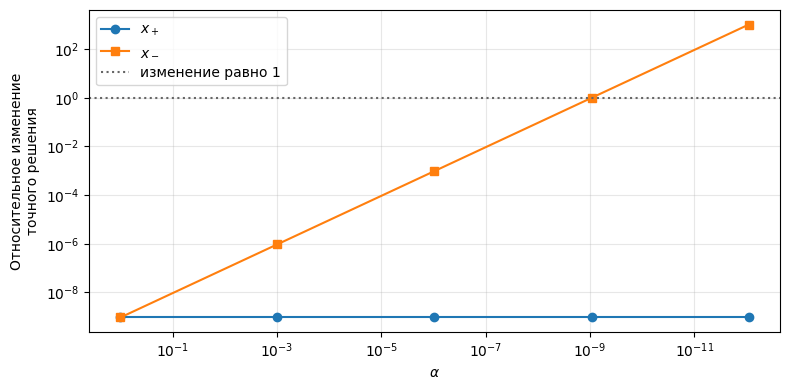

In [7]:
alphas: NDArray = 2.0 ** -np.array(DELTA_POWERS, dtype=np.float64)
fig, ax = plt.subplots(figsize=(8, 4))
ax.loglog(alphas, exact_changes[:, 1], "o-", label=r"$x_+$")
ax.loglog(alphas, exact_changes[:, 2], "s-", label=r"$x_-$")
ax.axhline(1, color="0.4", linestyle=":", label="изменение равно 1")
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel("Относительное изменение\nточного решения")
ax.invert_xaxis()
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Изменение $x_-$ достигает величины самого решения или превышает её при $\alpha\le2^{-30}$, то есть при $k=30$ и $k=40$ на заданной сетке, потому что $\theta/\alpha\ge1$.
Это возможно при малой обратной погрешности, потому что даже при точном решении системы возмущение правой части вдоль $v$ усиливается в $1/\alpha$ раз.


## Устойчивость: рост элементов при исключении

Матрица Уилкинсона $W\in\mathbb R^{n\times n}$ задаётся формулой:

$$
w_{ij}=\begin{cases}
1, & i=j\text{ или }j=n,\\
-1, & i>j\text{ и }j<n,\\
0, & \text{иначе}
\end{cases}
$$

Возьмите $n=8,16,32,48,64$, вектор $x^*=\mathbf 1_n$ из единиц и $b=Wx^*$.
При выборе ведущего элемента по столбцу, если несколько элементов имеют максимальный модуль, выбирайте верхний из них.


### 1. Рост элементов.

Объясните, почему при исключении строки не переставляются, а последний столбец $U$ содержит $1,2,4,\ldots,2^{n-1}$.
Вычислите коэффициент роста

$$
\rho_U=\frac{\max_{i,j}|u_{ij}|}{\max_{i,j}|w_{ij}|}
$$


Строки не переставляются, потому что до последнего шага ведущий элемент равен 1, под ним стоят $-1$, а при равенстве модулей выбирается верхний элемент.
Последний столбец $U$ содержит $1,2,4,\ldots,2^{n-1}$, потому что множители равны $-1$ и прибавление ведущей строки к нижним удваивает его ещё не исключённые элементы, значит,

$$
\rho_U=\frac{2^{n-1}}{1}=2^{n-1}.
$$


In [8]:
def wilkinson_matrix(n: int) -> NDArray:
    W: NDArray = np.eye(n, dtype=np.float64) - np.tril(np.ones((n, n)), -1)
    W[:, -1] = 1
    return W


wilkinson_factors: dict[int, tuple[NDArray, NDArray, NDArray]] = {}
growths: NDArray = np.empty(len(WILKINSON_SIZES))
rows = []
for i, n in enumerate(WILKINSON_SIZES):
    W: NDArray = wilkinson_matrix(n)
    L, U, p = lup_factor(W)
    wilkinson_factors[n] = (L, U, p)
    expected_column: NDArray = np.ldexp(np.ones(n), np.arange(n))
    assert np.array_equal(p, np.arange(n))
    assert np.array_equal(U[:, -1], expected_column)
    growths[i] = growth_factor(W, U)
    rows.append([str(n), "нет", f"{U[:, -1].max():.6e}", f"{growths[i]:.6e}"])
print(text_table(["n", "перестановки", "max |u_in|", "rho_U"], rows))

n   перестановки    max |u_in|         rho_U
--  ------------  ------------  ------------
8            нет  1.280000e+02  1.280000e+02
16           нет  3.276800e+04  3.276800e+04
32           нет  2.147484e+09  2.147484e+09
48           нет  1.407375e+14  1.407375e+14
64           нет  9.223372e+18  9.223372e+18


### 2. Точность решения.

Решите $Wx=b$ через LUP и QR. Для каждого $n$ вычислите относительную ошибку решения и обратную погрешность $\eta_{\mathrm{back},1}$.
Сравните их с $\rho_U$. Оцените $\widetilde\kappa_1(W)$ по QR-факторам.
Объясните, почему одной обусловленностью матрицы нельзя объяснить потерю точности LUP в этом опыте.


In [9]:
wilkinson_errors: NDArray = np.empty((len(WILKINSON_SIZES), len(METHODS)))
wilkinson_backward: NDArray = np.empty_like(wilkinson_errors)
wilkinson_kappas: NDArray = np.empty(len(WILKINSON_SIZES))
wilkinson_qr: dict[int, tuple[NDArray, NDArray]] = {}
rows = []
for i, n in enumerate(WILKINSON_SIZES):
    W: NDArray = wilkinson_matrix(n)
    x_exact: NDArray = np.ones(n, dtype=np.float64)
    b: NDArray = W @ x_exact
    L, U, p = wilkinson_factors[n]
    F, tau = qr_factor(W)
    wilkinson_qr[n] = (F, tau)
    wilkinson_kappas[i] = condition_1_estimate(W, lambda rhs: qr_solve(F, tau, rhs))
    computed = (lup_solve(L, U, p, b), qr_solve(F, tau, b))
    for m, (method, x) in enumerate(zip(METHODS, computed)):
        wilkinson_errors[i, m] = relative_error(x, x_exact)
        wilkinson_backward[i, m] = backward_error_1(W, x, b)
        rows.append(
            [
                str(n),
                method,
                f"{growths[i]:.3e}",
                f"{wilkinson_kappas[i]:.3e}",
                f"{wilkinson_errors[i, m]:.3e}",
                f"{wilkinson_backward[i, m]:.3e}",
            ]
        )
print(
    text_table(
        ["n", "метод", "rho_U", "kappa~_1 по QR", "ошибка решения", "eta_back,1"], rows
    )
)
assert np.allclose(wilkinson_kappas, WILKINSON_SIZES, rtol=1e-12, atol=0)
assert np.max(wilkinson_errors[:, 1]) < 1e-12

n   метод      rho_U  kappa~_1 по QR  ошибка решения  eta_back,1
--  -----  ---------  --------------  --------------  ----------
8     lup  1.280e+02       8.000e+00       0.000e+00   0.000e+00
8      qr  1.280e+02       8.000e+00       3.377e-16   3.879e-17
16    lup  3.277e+04       1.600e+01       0.000e+00   0.000e+00
16     qr  3.277e+04       1.600e+01       1.331e-15   7.844e-17
32    lup  2.147e+09       3.200e+01       0.000e+00   0.000e+00
32     qr  2.147e+09       3.200e+01       1.989e-15   7.498e-17
48    lup  1.407e+14       4.800e+01       0.000e+00   0.000e+00
48     qr  1.407e+14       4.800e+01       4.170e-15   6.964e-17
64    lup  9.223e+18       6.400e+01       2.163e+00   2.391e-02
64     qr  9.223e+18       6.400e+01       5.679e-15   1.134e-16


При $n\le48$ LUP возвращает точный вектор единиц, при $n=64$ рост $\rho_U\approx9.22\cdot10^{18}$ сопровождается ошибкой около $2.16$ и обратной погрешностью $0.024$.
У QR ошибка остаётся меньше $10^{-14}$, обратная погрешность имеет порядок $10^{-16}$.

Одной обусловленностью нельзя объяснить потерю точности LUP, потому что при $\widetilde\kappa_1(W)\approx n$ ориентир $\mathfrak u\widetilde\kappa_1\approx7.1\cdot10^{-15}$ для $n=64$ значительно меньше ошибки $2.16$, вызванной ростом элементов при исключении.


### 3. Влияние правой части.

При $n=64$ повторите опыт для $x^*=e_n$ и $b=Wx^*$, где $e_n$ $\text{---}$ последний вектор стандартного базиса.
Сравните ошибки с результатами для $x^*=\mathbf 1_n$.
Объясните, почему большой рост элементов не обязательно приводит к большой ошибке решения.


In [10]:
n = 64
W: NDArray = wilkinson_matrix(n)
x_last: NDArray = np.zeros(n, dtype=np.float64)
x_last[-1] = 1
b_last: NDArray = W @ x_last
L, U, p = wilkinson_factors[n]
F, tau = wilkinson_qr[n]
last_solutions = (lup_solve(L, U, p, b_last), qr_solve(F, tau, b_last))
last_errors: NDArray = np.empty(len(METHODS))
last_backward: NDArray = np.empty(len(METHODS))
rows = []
for m, (method, x) in enumerate(zip(METHODS, last_solutions)):
    last_errors[m] = relative_error(x, x_last)
    last_backward[m] = backward_error_1(W, x, b_last)
    rows.append(
        [
            "1_n",
            method,
            f"{wilkinson_errors[-1, m]:.3e}",
            f"{wilkinson_backward[-1, m]:.3e}",
        ]
    )
    rows.append(["e_n", method, f"{last_errors[m]:.3e}", f"{last_backward[m]:.3e}"])
print(text_table(["точное x", "метод", "ошибка решения", "eta_back,1"], rows))
assert np.array_equal(last_solutions[0], x_last)

точное x  метод  ошибка решения  eta_back,1
--------  -----  --------------  ----------
1_n         lup       2.163e+00   2.391e-02
e_n         lup       0.000e+00   0.000e+00
1_n          qr       5.679e-15   1.134e-16
e_n          qr       4.794e-15   4.155e-16


При $x^*=e_n$ ошибка LUP и вычисленная обратная погрешность равны нулю вместо ошибки $2.16$ для $x^*=\mathbf1_n$ при том же $\rho_U=2^{63}$, у QR ошибка остаётся порядка $10^{-15}$.

Большой рост элементов не обязательно приводит к большой ошибке, потому что здесь $b=\mathbf1_n$, прямая подстановка даёт точно представимые степени двойки $1,2,4,\ldots,2^{63}$, а обратная возвращает $e_n$ без округлений.
